# **Pattern Recognition: Combined Notebook**

### **Imports**

In [20]:
import numpy as np
import matplotlib.pyplot as plt

### **Dataset Paths**

In [21]:
import os

DATA_DIR =r"D:\M.Tech\PR and ML\Assignment 8"

for name in ["synthetic", "image_features", "mnist", "tdigits"]:
    print(f"{name:15}", "found" if os.path.isdir(os.path.join(DATA_DIR, name)) else "NOT FOUND",
          "->", os.path.abspath(os.path.join(DATA_DIR, name)))


synthetic       found -> D:\M.Tech\PR and ML\Assignment 8\synthetic
image_features  found -> D:\M.Tech\PR and ML\Assignment 8\image_features
mnist           found -> D:\M.Tech\PR and ML\Assignment 8\mnist
tdigits         found -> D:\M.Tech\PR and ML\Assignment 8\tdigits


In [22]:
def plot_pca_2d(X, y):
    pca = PCA(k=2).fit(X)
    points = pca.transform(X)

    plt.figure(figsize=(7, 5))
    for label in np.unique(y):
        selected = y == label
        plt.scatter(points[selected, 0], points[selected, 1],
                    s=10, alpha=0.5, edgecolors="none", label=str(label))
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title("Training data (2D PCA)")
    plt.legend(title="Class")
    plt.tight_layout()
    plt.show()

## **Library Code**

### **K-Means**

In [23]:
class KMeans:
    def __init__(self, K=3):
        self.K = K
        self.centers = None

    def fit(self, X):
        # Deterministic start: sort points along the direction of largest
        # variance and take K evenly spaced points from that ordering.
        centered = X - X.mean(axis=0)
        _, _, directions = np.linalg.svd(centered, full_matrices=False)
        order = np.argsort(centered @ directions[0], kind="stable")
        positions = ((np.arange(self.K) + 0.5) * len(X) / self.K).astype(int)
        self.centers = X[order[positions]].astype(float)

        for _ in range(100):
            labels = self.predict(X)
            new_centers = self.centers.copy()

            for k in range(self.K):
                points = X[labels == k]
                if len(points) > 0:
                    new_centers[k] = points.mean(axis=0)

            converged = np.max(np.abs(self.centers - new_centers)) < 1e-6
            self.centers = new_centers
            if converged:
                break

        return self

    def predict(self, X):
        if self.centers is None:
            raise ValueError("Call fit() before predict().")

        labels = []
        for point in X:
            distances = [np.sum((point - center) ** 2) for center in self.centers]
            labels.append(np.argmin(distances))

        return np.array(labels, dtype=int)


### **GMM**

In [24]:
class GMM:
    def __init__(self, K=3, reg=1e-6, max_iter=100, tol=1e-6):
        self.K = K
        self.reg = reg
        self.max_iter = max_iter
        self.tol = tol
        self.weights = None
        self.means = None
        self.covariances = None
        self.log_likelihoods = []

    def component_scores(self, X):
        n, d = X.shape
        scores = np.zeros((n, self.K))

        for k in range(self.K):
            difference = X - self.means[k]
            eigenvalues = np.linalg.eigvalsh(self.covariances[k])
            if np.any(eigenvalues <= 0):
                raise ValueError("Covariance must be positive definite. Try a larger reg.")
            # Log determinant = sum of the logs of the eigenvalues.
            log_det = np.log(eigenvalues).sum()
            inverse_covariance = np.linalg.inv(self.covariances[k])
            # Quadratic term: (x - mean).T @ inverse_covariance @ (x - mean)
            d_squared = np.sum((difference @ inverse_covariance) * difference, axis=1)
            scores[:, k] = np.log(self.weights[k]) - 0.5 * (
                d * np.log(2 * np.pi) + log_det + d_squared
            )

        return scores

    def score_samples(self, X):
        # log of the mixture density, calculated without tiny exponentials
        scores = self.component_scores(X)
        largest = scores.max(axis=1)
        return largest + np.log(np.exp(scores - largest[:, None]).sum(axis=1))

    def fit(self, X):
        n, d = X.shape
        model = KMeans(K=self.K)
        model.fit(X)
        labels = model.predict(X)

        self.means = model.centers.copy()
        self.weights = np.zeros(self.K)
        self.covariances = np.zeros((self.K, d, d))
        self.log_likelihoods = []

        for k in range(self.K):
            points = X[labels == k]
            if len(points) == 0:
                raise ValueError("K-means produced an empty component. Try another K.")
            difference = points - self.means[k]
            self.weights[k] = len(points) / n
            self.covariances[k] = difference.T @ difference / len(points)
            self.covariances[k] += self.reg * np.eye(d)

        for _ in range(self.max_iter):
            # E-step: soft membership of each point in each component
            scores = self.component_scores(X)
            scores -= scores.max(axis=1, keepdims=True)
            responsibilities = np.exp(scores)
            responsibilities /= responsibilities.sum(axis=1, keepdims=True)

            # M-step: update weights, means, and covariances
            counts = responsibilities.sum(axis=0)
            if np.any(counts < 1e-10):
                raise ValueError("A component has no effective points. Try a smaller K.")
            self.weights = counts / n
            self.means = responsibilities.T @ X / counts[:, None]

            for k in range(self.K):
                difference = X - self.means[k]
                weighted_difference = responsibilities[:, k, None] * difference
                self.covariances[k] = difference.T @ weighted_difference / counts[k]
                self.covariances[k] += self.reg * np.eye(d)

            log_likelihood = self.score_samples(X).mean()
            self.log_likelihoods.append(log_likelihood)
            if len(self.log_likelihoods) > 1:
                change = self.log_likelihoods[-1] - self.log_likelihoods[-2]
                if abs(change) < self.tol:
                    break

        return self


### **KNN**

In [25]:
class KNN:
    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        self.X = X
        self.y = y
        return self

    def predict(self, X):
        predictions = []
        for point in X:
            distances = np.sum((self.X - point) ** 2, axis=1)
            nearest = np.argsort(distances)[:self.k]
            labels, counts = np.unique(self.y[nearest], return_counts=True)
            predictions.append(labels[np.argmax(counts)])
        return np.array(predictions)


### **LDA**

In [26]:
class LDA:
    def __init__(self, reg=1e-3):
        self.reg = reg

    def fit(self, X, y):
        self.classes = np.unique(y)
        n, d = X.shape
        means = []
        priors = []
        covariance = np.zeros((d, d))

        for label in self.classes:
            samples = X[y == label]
            mean = samples.mean(axis=0)
            means.append(mean)
            priors.append(len(samples) / n)
            difference = samples - mean
            covariance += difference.T @ difference

        self.means = np.array(means)
        self.covariance = covariance / n + self.reg * np.eye(d)
        self.weights = np.linalg.solve(self.covariance, self.means.T).T
        self.bias = -0.5 * np.sum(self.means * self.weights, axis=1) + np.log(priors)
        return self

    def predict(self, X):
        scores = X @ self.weights.T + self.bias
        return self.classes[np.argmax(scores, axis=1)]


### **PCA**

In [27]:
class PCA:
    def __init__(self, k):
        self.k = k

    def fit(self, X):
        if not 1 <= self.k <= X.shape[1]:
            raise ValueError("k must be between 1 and the number of features.")
        self.mean = X.mean(axis=0)
        centered = X - self.mean
        covariance = centered.T @ centered / len(X)
        eigenvalues, eigenvectors = np.linalg.eigh(covariance)
        order = np.argsort(eigenvalues)[::-1]
        self.components = eigenvectors[:, order[:self.k]]
        return self

    def transform(self, X):
        return (X - self.mean) @ self.components


### **SVM**

In [28]:
class SVM:
    def __init__(self, sigma=None, tol=1e-3, max_iter=100000):
        self.sigma = sigma
        self.tol = tol
        self.max_iter = max_iter

    def kernel(self, X, Z):
        distances = (np.sum(X ** 2, axis=1)[:, None]
                     + np.sum(Z ** 2, axis=1) - 2 * X @ Z.T)
        np.maximum(distances, 0, out=distances)
        distances *= -1 / (2 * self.width ** 2)
        np.exp(distances, out=distances)
        return distances

    def fit_binary(self, X, y, K):
        alpha = np.zeros(len(y))
        gradient = y.astype(float).copy()

        for _ in range(self.max_iter):
            upper = (y == 1) | (alpha > 0)
            lower = (y == -1) | (alpha > 0)
            i = np.argmax(np.where(upper, gradient, -np.inf))
            j = np.argmin(np.where(lower, gradient, np.inf))
            gap = gradient[i] - gradient[j]
            if gap <= self.tol:
                gradient = y - K @ (alpha * y)
                if gradient[upper].max() - gradient[lower].min() <= self.tol:
                    break
                continue

            limit = min(alpha[i] if y[i] == -1 else np.inf,
                        alpha[j] if y[j] == 1 else np.inf)
            curvature = K[i, i] + K[j, j] - 2 * K[i, j]
            if curvature <= 0:
                if np.isinf(limit):
                    raise ValueError("Hard-margin separation failed at this kernel width.")
                step = limit
            else:
                step = min(gap / curvature, limit)
            alpha[i] += y[i] * step
            alpha[j] -= y[j] * step
            gradient -= step * (K[:, i] - K[:, j])

        gradient = y - K @ (alpha * y)
        upper = (y == 1) | (alpha > 0)
        lower = (y == -1) | (alpha > 0)
        gap = gradient[upper].max() - gradient[lower].min()
        support = alpha > 0
        bias = gradient[support].mean()
        return X[support], alpha[support] * y[support], bias, gap

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes = np.unique(y)
        self.width = self.sigma
        if self.width is None:
            self.width = np.sqrt(X.var(axis=0).sum()) / 2
        if self.width <= 0:
            raise ValueError("sigma must be positive.")
        self.models = []
        self.gaps = []

        K = self.kernel(X, X)
        np.fill_diagonal(K, 1.0)
        targets = self.classes if len(self.classes) > 2 else self.classes[:1]
        for label in targets:
            labels = np.where(y == label, 1, -1)
            points, coefficients, bias, gap = self.fit_binary(X, labels, K)
            self.models.append((points, coefficients, bias))
            self.gaps.append(gap)
        self.converged = all(gap <= self.tol for gap in self.gaps)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        scores = np.column_stack([self.kernel(X, points) @ coefficients + bias
                                  for points, coefficients, bias in self.models])
        if len(self.classes) == 2:
            return np.where(scores[:, 0] >= 0, self.classes[0], self.classes[1])
        return self.classes[np.argmax(scores, axis=1)]


## **Synthetic Data**

### **Load Data**

In [29]:
import os
print("Notebook is running in:", os.getcwd())
print("Contents here:", os.listdir("."))

if os.path.isdir(DATA_DIR):
    for name in os.listdir(DATA_DIR):
        full = os.path.join(DATA_DIR, name)
        if os.path.isdir(full):
            print(name, "->", os.listdir(full)[:10])
else:
    print(DATA_DIR, "is not in this folder")

Notebook is running in: d:\M.Tech\PR and ML\Assignment 8
Contents here: ['image_features', 'mnist', 'prml_08.ipynb', 'synthetic', 'tdigits']
image_features -> ['test_data.csv', 'test_label.csv', 'train_data.csv', 'train_label.csv', 'val_data.csv', 'val_label.csv']
mnist -> ['dev', 'test', 'train']
synthetic -> ['data.pkl', 'data_plot.png']
tdigits -> ['2.npz', '4.npz', '8.npz', 'feature_extraction.py', 'mapping.py']


In [30]:
import pickle

with open(os.path.join(DATA_DIR, "synthetic", "data.pkl"), "rb") as file:
    data = pickle.load(file)
X = data["x"]
y = data["y"]

print(X.shape)
print(y.shape)

(20000, 16)
(20000,)


### **Shuffle and Split**

In [31]:
import numpy as np
indices = np.arange(len(y))
# Deterministic stratified split: within each class, every 5 consecutive
# samples go 3 -> train, 1 -> validation, 1 -> test (60/20/20).
slot = np.zeros(len(y), dtype=int)
for label in np.unique(y):
    members = indices[y == label]
    slot[members] = np.arange(len(members)) % 5

train_indices = indices[slot < 3]
val_indices = indices[slot == 3]
test_indices = indices[slot == 4]

X_train = X[train_indices]
y_train = y[train_indices]
X_val = X[val_indices]
y_val = y[val_indices]
X_test = X[test_indices]
y_test = y[test_indices]


In [32]:
classes = np.unique(y_train)
print("Class order:", classes)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Class order: [0 1]
Train: (12000, 16)
Validation: (4000, 16)
Test: (4000, 16)


### **2D PCA Visualization**

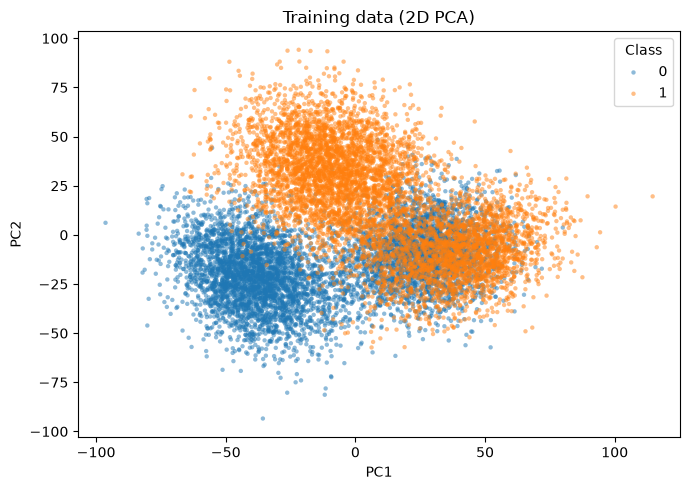

In [33]:
plot_pca_2d(X_train, y_train)


### **GMM**

In [34]:
models = []
priors = []
for label in classes:
    samples = X_train[y_train == label]
    model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    model.fit(samples)
    models.append(model)
    priors.append(len(samples) / len(X_train))
    print("Class", label, "EM iterations:", len(model.log_likelihoods))
    if len(model.log_likelihoods) == model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 0 EM iterations: 6
Class 1 EM iterations: 5


In [35]:
val_scores = np.column_stack([model.score_samples(X_val) for model in models])
gmm_val_predictions = classes[np.argmax(val_scores + np.log(priors), axis=1)]

test_scores = np.column_stack([model.score_samples(X_test) for model in models])
gmm_test_predictions = classes[np.argmax(test_scores + np.log(priors), axis=1)]


In [36]:
# Confusion matrix
gmm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_confusion)


Validation accuracy: 0.99975
Test accuracy: 1.0
Test confusion matrix:
 [[2000    0]
 [   0 2000]]


### **KNN**

In [37]:
knn = KNN(k=5)
knn.fit(X_train, y_train)
knn_val_predictions = knn.predict(X_val)
knn_test_predictions = knn.predict(X_test)


In [38]:
# Confusion matrix
knn_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_test_predictions == y_test))
print("Test confusion matrix:\n", knn_confusion)


Validation accuracy: 0.99525
Test accuracy: 0.9935
Test confusion matrix:
 [[1993    7]
 [  19 1981]]


### **LDA**

In [39]:
lda = LDA()
lda.fit(X_train, y_train)
lda_val_predictions = lda.predict(X_val)
lda_test_predictions = lda.predict(X_test)


In [40]:
# Confusion matrix
lda_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_test_predictions == y_test))
print("Test confusion matrix:\n", lda_confusion)


Validation accuracy: 0.9295
Test accuracy: 0.92325
Test confusion matrix:
 [[1822  178]
 [ 129 1871]]


### **SVM**

In [41]:
svm = SVM()
svm.fit(X_train, y_train)
print("One-vs-rest classifiers:", len(svm.models))
print("Gaussian sigma:", svm.width)
print("Converged:", svm.converged)
print("Largest KKT gap:", max(svm.gaps))
if not svm.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_val_predictions = svm.predict(X_val)
svm_test_predictions = svm.predict(X_test)


One-vs-rest classifiers: 1
Gaussian sigma: 38.02067363447495
Converged: True
Largest KKT gap: 0.0009989930952079007


In [42]:
# Confusion matrix
svm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_test_predictions == y_test))
print("Test confusion matrix:\n", svm_confusion)


Validation accuracy: 0.9965
Test accuracy: 0.997
Test confusion matrix:
 [[1997    3]
 [   9 1991]]


### **PCA**

In [43]:
K = 8
pca = PCA(k=K)
pca.fit(X_train)
X_train_pca = pca.transform(X_train)
X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test)

print("Train:", X_train_pca.shape)
print("Validation:", X_val_pca.shape)
print("Test:", X_test_pca.shape)


Train: (12000, 8)
Validation: (4000, 8)
Test: (4000, 8)


### **GMM with PCA**

In [44]:
pca_models = []
pca_priors = []
for label in classes:
    pca_samples = X_train_pca[y_train == label]
    pca_model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    pca_model.fit(pca_samples)
    pca_models.append(pca_model)
    pca_priors.append(len(pca_samples) / len(X_train_pca))
    print("Class", label, "EM iterations:", len(pca_model.log_likelihoods))
    if len(pca_model.log_likelihoods) == pca_model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 0 EM iterations: 28
Class 1 EM iterations: 29


In [45]:
pca_val_scores = np.column_stack([pca_model.score_samples(X_val_pca) for pca_model in pca_models])
gmm_pca_val_predictions = classes[np.argmax(pca_val_scores + np.log(pca_priors), axis=1)]

pca_test_scores = np.column_stack([pca_model.score_samples(X_test_pca) for pca_model in pca_models])
gmm_pca_test_predictions = classes[np.argmax(pca_test_scores + np.log(pca_priors), axis=1)]


In [46]:
# Confusion matrix
gmm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_pca_confusion)


Validation accuracy: 0.9675
Test accuracy: 0.9605
Test confusion matrix:
 [[1922   78]
 [  80 1920]]


### **KNN with PCA**

In [47]:
knn_pca = KNN(k=5)
knn_pca.fit(X_train_pca, y_train)
knn_pca_val_predictions = knn_pca.predict(X_val_pca)
knn_pca_test_predictions = knn_pca.predict(X_test_pca)


In [48]:
# Confusion matrix
knn_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_pca_test_predictions == y_test))
print("Test confusion matrix:\n", knn_pca_confusion)


Validation accuracy: 0.951
Test accuracy: 0.9475
Test confusion matrix:
 [[1892  108]
 [ 102 1898]]


### **LDA with PCA**

In [49]:
lda_pca = LDA()
lda_pca.fit(X_train_pca, y_train)
lda_pca_val_predictions = lda_pca.predict(X_val_pca)
lda_pca_test_predictions = lda_pca.predict(X_test_pca)


In [50]:
# Confusion matrix
lda_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_pca_test_predictions == y_test))
print("Test confusion matrix:\n", lda_pca_confusion)


Validation accuracy: 0.85125
Test accuracy: 0.84275
Test confusion matrix:
 [[1614  386]
 [ 243 1757]]


### **SVM with PCA**

In [51]:
svm_pca = SVM(max_iter=1000000)
svm_pca.fit(X_train_pca, y_train)
print("One-vs-rest classifiers:", len(svm_pca.models))
print("Gaussian sigma:", svm_pca.width)
print("Converged:", svm_pca.converged)
print("Largest KKT gap:", max(svm_pca.gaps))
if not svm_pca.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_pca_val_predictions = svm_pca.predict(X_val_pca)
svm_pca_test_predictions = svm_pca.predict(X_test_pca)


One-vs-rest classifiers: 1
Gaussian sigma: 32.791930757550624
Converged: False
Largest KKT gap: 0.0061274639219845994
Iteration limit reached; not a converged hard-margin solution.


In [52]:
# Confusion matrix
svm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", svm_pca_confusion)


Validation accuracy: 0.9265
Test accuracy: 0.919
Test confusion matrix:
 [[1825  175]
 [ 149 1851]]


### **Accuracy Comparison**

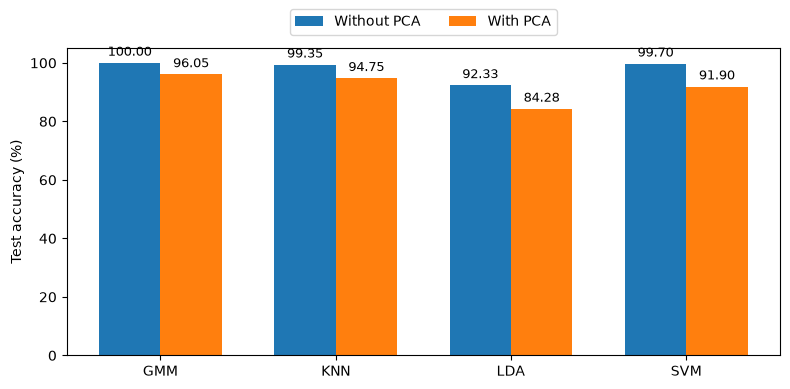

In [53]:
original_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                     [gmm_confusion, knn_confusion, lda_confusion, svm_confusion]]
pca_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                [gmm_pca_confusion, knn_pca_confusion, lda_pca_confusion, svm_pca_confusion]]
positions = np.arange(4)
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
original_bars = ax.bar(positions - width / 2, original_accuracy, width, label="Without PCA")
pca_bars = ax.bar(positions + width / 2, pca_accuracy, width, label="With PCA")
ax.bar_label(original_bars, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(pca_bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(positions, ["GMM", "KNN", "LDA", "SVM"])
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 105)
ax.set_yticks(np.arange(0, 101, 20))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=2)
plt.tight_layout()
plt.show()


## **D2 / Image Features**

### **Load Data**

In [54]:
def load_split(split):
    X = np.loadtxt(os.path.join(DATA_DIR, "image_features", f"{split}_data.csv"), delimiter=",")
    y = np.loadtxt(os.path.join(DATA_DIR, "image_features", f"{split}_label.csv"), delimiter=",").astype(int)
    return X, y


X_train, y_train = load_split("train")
X_val, y_val = load_split("val")
X_test, y_test = load_split("test")


In [55]:
classes = np.unique(y_train)
print("Class order:", classes)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Class order: [0 1 2 3 4]
Train: (2000, 36)
Validation: (500, 36)
Test: (500, 36)


### **2D PCA Visualization**

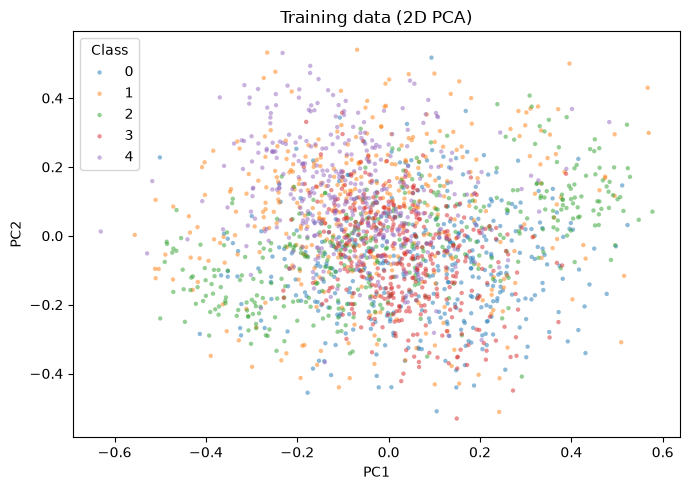

In [56]:
plot_pca_2d(X_train, y_train)


### **GMM**

In [57]:
models = []
priors = []
for label in classes:
    samples = X_train[y_train == label]
    model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    model.fit(samples)
    models.append(model)
    priors.append(len(samples) / len(X_train))
    print("Class", label, "EM iterations:", len(model.log_likelihoods))
    if len(model.log_likelihoods) == model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 0 EM iterations: 40
Class 1 EM iterations: 18
Class 2 EM iterations: 12
Class 3 EM iterations: 36
Class 4 EM iterations: 50


In [58]:
val_scores = np.column_stack([model.score_samples(X_val) for model in models])
gmm_val_predictions = classes[np.argmax(val_scores + np.log(priors), axis=1)]

test_scores = np.column_stack([model.score_samples(X_test) for model in models])
gmm_test_predictions = classes[np.argmax(test_scores + np.log(priors), axis=1)]


In [59]:
# Confusion matrix
gmm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_confusion)


Validation accuracy: 0.566
Test accuracy: 0.578
Test confusion matrix:
 [[57  7  9 21  6]
 [17 52 11  4 16]
 [ 6  4 63 20  7]
 [14  5 12 67  2]
 [14 14  8 14 50]]


### **KNN**

In [60]:
knn = KNN(k=5)
knn.fit(X_train, y_train)
knn_val_predictions = knn.predict(X_val)
knn_test_predictions = knn.predict(X_test)


In [61]:
# Confusion matrix
knn_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_test_predictions == y_test))
print("Test confusion matrix:\n", knn_confusion)


Validation accuracy: 0.524
Test accuracy: 0.522
Test confusion matrix:
 [[59  2  9 20 10]
 [24 41 11 11 13]
 [15  1 61 13 10]
 [20  6 13 56  5]
 [17 17  7 15 44]]


### **LDA**

In [62]:
lda = LDA()
lda.fit(X_train, y_train)
lda_val_predictions = lda.predict(X_val)
lda_test_predictions = lda.predict(X_test)


In [63]:
# Confusion matrix
lda_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_test_predictions == y_test))
print("Test confusion matrix:\n", lda_confusion)


Validation accuracy: 0.56
Test accuracy: 0.566
Test confusion matrix:
 [[63  5 12 12  8]
 [14 44 12  8 22]
 [14  1 61 12 12]
 [15  0 13 61 11]
 [15 10  9 12 54]]


### **SVM**

In [64]:
svm = SVM()
svm.fit(X_train, y_train)
print("One-vs-rest classifiers:", len(svm.models))
print("Gaussian sigma:", svm.width)
print("Converged:", svm.converged)
print("Largest KKT gap:", max(svm.gaps))
if not svm.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_val_predictions = svm.predict(X_val)
svm_test_predictions = svm.predict(X_test)


One-vs-rest classifiers: 5
Gaussian sigma: 0.25729675591754103
Converged: True
Largest KKT gap: 0.0009988383770040965


In [65]:
# Confusion matrix
svm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_test_predictions == y_test))
print("Test confusion matrix:\n", svm_confusion)


Validation accuracy: 0.61
Test accuracy: 0.618
Test confusion matrix:
 [[57  9  9 14 11]
 [12 69  6  1 12]
 [ 9  4 60 12 15]
 [ 9  4  9 69  9]
 [ 9 15  8 14 54]]


### **PCA**

In [66]:
K = 18
pca = PCA(k=K)
pca.fit(X_train)
X_train_pca = pca.transform(X_train)
X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test)

print("Train:", X_train_pca.shape)
print("Validation:", X_val_pca.shape)
print("Test:", X_test_pca.shape)


Train: (2000, 18)
Validation: (500, 18)
Test: (500, 18)


### **GMM with PCA**

In [67]:
pca_models = []
pca_priors = []
for label in classes:
    pca_samples = X_train_pca[y_train == label]
    pca_model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    pca_model.fit(pca_samples)
    pca_models.append(pca_model)
    pca_priors.append(len(pca_samples) / len(X_train_pca))
    print("Class", label, "EM iterations:", len(pca_model.log_likelihoods))
    if len(pca_model.log_likelihoods) == pca_model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 0 EM iterations: 100
Iteration limit reached; convergence is not guaranteed.
Class 1 EM iterations: 30
Class 2 EM iterations: 18
Class 3 EM iterations: 31
Class 4 EM iterations: 34


In [68]:
pca_val_scores = np.column_stack([pca_model.score_samples(X_val_pca) for pca_model in pca_models])
gmm_pca_val_predictions = classes[np.argmax(pca_val_scores + np.log(pca_priors), axis=1)]

pca_test_scores = np.column_stack([pca_model.score_samples(X_test_pca) for pca_model in pca_models])
gmm_pca_test_predictions = classes[np.argmax(pca_test_scores + np.log(pca_priors), axis=1)]


In [69]:
# Confusion matrix
gmm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_pca_confusion)


Validation accuracy: 0.61
Test accuracy: 0.6
Test confusion matrix:
 [[55  9  7 20  9]
 [13 54  9  7 17]
 [16  2 62 14  6]
 [15  0  9 70  6]
 [ 8 10  5 18 59]]


### **KNN with PCA**

In [70]:
knn_pca = KNN(k=5)
knn_pca.fit(X_train_pca, y_train)
knn_pca_val_predictions = knn_pca.predict(X_val_pca)
knn_pca_test_predictions = knn_pca.predict(X_test_pca)


In [71]:
# Confusion matrix
knn_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_pca_test_predictions == y_test))
print("Test confusion matrix:\n", knn_pca_confusion)


Validation accuracy: 0.546
Test accuracy: 0.514
Test confusion matrix:
 [[59  4 12 20  5]
 [29 34 13  8 16]
 [13  3 60 13 11]
 [27  2  8 57  6]
 [16 13 10 14 47]]


### **LDA with PCA**

In [72]:
lda_pca = LDA()
lda_pca.fit(X_train_pca, y_train)
lda_pca_val_predictions = lda_pca.predict(X_val_pca)
lda_pca_test_predictions = lda_pca.predict(X_test_pca)


In [73]:
# Confusion matrix
lda_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_pca_test_predictions == y_test))
print("Test confusion matrix:\n", lda_pca_confusion)


Validation accuracy: 0.58
Test accuracy: 0.576
Test confusion matrix:
 [[63  5 12 12  8]
 [14 46 16  5 19]
 [14  1 61 12 12]
 [16  1 10 61 12]
 [14  8  9 12 57]]


### **SVM with PCA**

In [74]:
svm_pca = SVM()
svm_pca.fit(X_train_pca, y_train)
print("One-vs-rest classifiers:", len(svm_pca.models))
print("Gaussian sigma:", svm_pca.width)
print("Converged:", svm_pca.converged)
print("Largest KKT gap:", max(svm_pca.gaps))
if not svm_pca.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_pca_val_predictions = svm_pca.predict(X_val_pca)
svm_pca_test_predictions = svm_pca.predict(X_test_pca)


One-vs-rest classifiers: 5
Gaussian sigma: 0.2347835573631995
Converged: True
Largest KKT gap: 0.0009993202484306352


In [75]:
# Confusion matrix
svm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", svm_pca_confusion)


Validation accuracy: 0.578
Test accuracy: 0.576
Test confusion matrix:
 [[44  9 18 16 13]
 [14 70  7  1  8]
 [10  4 61 12 13]
 [12  4 11 62 11]
 [11 15  7 16 51]]


### **Accuracy Comparison**

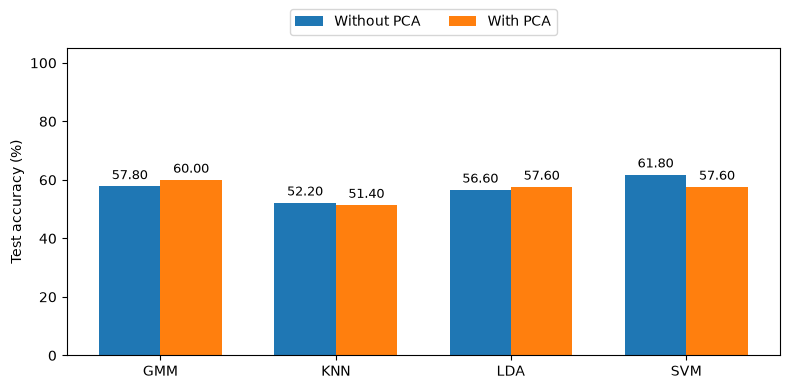

In [76]:
original_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                     [gmm_confusion, knn_confusion, lda_confusion, svm_confusion]]
pca_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                [gmm_pca_confusion, knn_pca_confusion, lda_pca_confusion, svm_pca_confusion]]
positions = np.arange(4)
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
original_bars = ax.bar(positions - width / 2, original_accuracy, width, label="Without PCA")
pca_bars = ax.bar(positions + width / 2, pca_accuracy, width, label="With PCA")
ax.bar_label(original_bars, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(pca_bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(positions, ["GMM", "KNN", "LDA", "SVM"])
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 105)
ax.set_yticks(np.arange(0, 101, 20))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=2)
plt.tight_layout()
plt.show()


## **MNIST**

### **Load Data**

In [78]:
import os
from PIL import Image


def load_images(folder):
    images = []
    labels = []
    for digit in [0, 6,9]:
        digit_folder = os.path.join(folder, str(digit))
        for filename in sorted(os.listdir(digit_folder)):
            if filename.endswith(".png"):
                with Image.open(os.path.join(digit_folder, filename)) as image:
                    pixels = np.array(image.convert("L"), dtype=float)
                    images.append(pixels.ravel() / 255.0)
                    labels.append(digit)
    return np.array(images), np.array(labels)


X_train, y_train = load_images(os.path.join(DATA_DIR, "mnist", "train"))
X_val, y_val = load_images(os.path.join(DATA_DIR, "mnist", "dev"))
X_test, y_test = load_images(os.path.join(DATA_DIR, "mnist", "test"))


In [79]:
classes = np.unique(y_train)
print("Class order:", classes)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Class order: [0 6 9]
Train: (14263, 784)
Validation: (3527, 784)
Test: (2947, 784)


### **2D PCA Visualization**

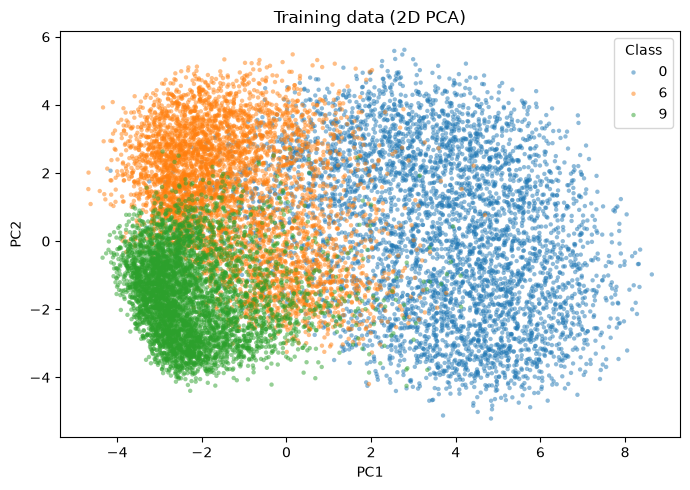

In [80]:
plot_pca_2d(X_train, y_train)

### **GMM**

In [81]:
models = []
priors = []
for label in classes:
    samples = X_train[y_train == label]
    model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    model.fit(samples)
    models.append(model)
    priors.append(len(samples) / len(X_train))
    print("Class", label, "EM iterations:", len(model.log_likelihoods))
    if len(model.log_likelihoods) == model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 0 EM iterations: 19
Class 6 EM iterations: 31
Class 9 EM iterations: 38


In [82]:
val_scores = np.column_stack([model.score_samples(X_val) for model in models])
gmm_val_predictions = classes[np.argmax(val_scores + np.log(priors), axis=1)]

test_scores = np.column_stack([model.score_samples(X_test) for model in models])
gmm_test_predictions = classes[np.argmax(test_scores + np.log(priors), axis=1)]


In [83]:
# Confusion matrix
gmm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_confusion)


Validation accuracy: 0.9844060107740289
Test accuracy: 0.9830335934848999
Test confusion matrix:
 [[976   2   2]
 [ 20 937   1]
 [ 24   1 984]]


### **KNN**

In [84]:
knn = KNN(k=5)
knn.fit(X_train, y_train)
knn_val_predictions = knn.predict(X_val)
knn_test_predictions = knn.predict(X_test)

In [85]:
# Confusion matrix
knn_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_test_predictions == y_test))
print("Test confusion matrix:\n", knn_confusion)


Validation accuracy: 0.9934788772327757
Test accuracy: 0.99151679674245
Test confusion matrix:
 [[973   6   1]
 [  7 951   0]
 [ 10   1 998]]


### **LDA**

In [86]:
lda = LDA()
lda.fit(X_train, y_train)
lda_val_predictions = lda.predict(X_val)
lda_test_predictions = lda.predict(X_test)


In [87]:
# Confusion matrix
lda_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_test_predictions == y_test))
print("Test confusion matrix:\n", lda_confusion)


Validation accuracy: 0.9821377941593422
Test accuracy: 0.9793009840515778
Test confusion matrix:
 [[960  14   6]
 [ 15 942   1]
 [ 20   5 984]]


### **SVM**

In [88]:
svm = SVM()
svm.fit(X_train, y_train)
print("One-vs-rest classifiers:", len(svm.models))
print("Gaussian sigma:", svm.width)
print("Converged:", svm.converged)
print("Largest KKT gap:", max(svm.gaps))
if not svm.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_val_predictions = svm.predict(X_val)
svm_test_predictions = svm.predict(X_test)


One-vs-rest classifiers: 3
Gaussian sigma: 3.6765322752013754
Converged: True
Largest KKT gap: 0.0009959151578640135


In [89]:
# Confusion matrix
svm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_test_predictions == y_test))
print("Test confusion matrix:\n", svm_confusion)


Validation accuracy: 0.9951800396937908
Test accuracy: 0.9949100780454699
Test confusion matrix:
 [[ 976    3    1]
 [   6  951    1]
 [   3    1 1005]]


### **PCA**

In [90]:
K = 50
pca = PCA(k=K)
pca.fit(X_train)
X_train_pca = pca.transform(X_train)
X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test)

print("Train:", X_train_pca.shape)
print("Validation:", X_val_pca.shape)
print("Test:", X_test_pca.shape)


Train: (14263, 50)
Validation: (3527, 50)
Test: (2947, 50)


### **GMM with PCA**

In [91]:
pca_models = []
pca_priors = []
for label in classes:
    pca_samples = X_train_pca[y_train == label]
    pca_model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    pca_model.fit(pca_samples)
    pca_models.append(pca_model)
    pca_priors.append(len(pca_samples) / len(X_train_pca))
    print("Class", label, "EM iterations:", len(pca_model.log_likelihoods))
    if len(pca_model.log_likelihoods) == pca_model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 0 EM iterations: 25
Class 6 EM iterations: 60
Class 9 EM iterations: 52


In [92]:
pca_val_scores = np.column_stack([pca_model.score_samples(X_val_pca) for pca_model in pca_models])
gmm_pca_val_predictions = classes[np.argmax(pca_val_scores + np.log(pca_priors), axis=1)]

pca_test_scores = np.column_stack([pca_model.score_samples(X_test_pca) for pca_model in pca_models])
gmm_pca_test_predictions = classes[np.argmax(pca_test_scores + np.log(pca_priors), axis=1)]


In [93]:
# Confusion matrix
gmm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_pca_confusion)


Validation accuracy: 0.9946129855401191
Test accuracy: 0.995588734306074
Test confusion matrix:
 [[ 979    0    1]
 [   6  947    5]
 [   1    0 1008]]


### **KNN with PCA**

In [94]:
knn_pca = KNN(k=5)
knn_pca.fit(X_train_pca, y_train)
knn_pca_val_predictions = knn_pca.predict(X_val_pca)
knn_pca_test_predictions = knn_pca.predict(X_test_pca)


In [95]:
# Confusion matrix
knn_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_pca_test_predictions == y_test))
print("Test confusion matrix:\n", knn_pca_confusion)


Validation accuracy: 0.9943294584632832
Test accuracy: 0.993892093654564
Test confusion matrix:
 [[ 974    5    1]
 [   5  953    0]
 [   6    1 1002]]


### **LDA with PCA**

In [96]:
lda_pca = LDA()
lda_pca.fit(X_train_pca, y_train)
lda_pca_val_predictions = lda_pca.predict(X_val_pca)
lda_pca_test_predictions = lda_pca.predict(X_test_pca)


In [97]:
# Confusion matrix
lda_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_pca_test_predictions == y_test))
print("Test confusion matrix:\n", lda_pca_confusion)


Validation accuracy: 0.9801531046214913
Test accuracy: 0.9820156090939939
Test confusion matrix:
 [[969   8   3]
 [ 17 938   3]
 [ 15   7 987]]


### **SVM with PCA**

In [98]:
svm_pca = SVM()
svm_pca.fit(X_train_pca, y_train)
print("One-vs-rest classifiers:", len(svm_pca.models))
print("Gaussian sigma:", svm_pca.width)
print("Converged:", svm_pca.converged)
print("Largest KKT gap:", max(svm_pca.gaps))
if not svm_pca.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_pca_val_predictions = svm_pca.predict(X_val_pca)
svm_pca_test_predictions = svm_pca.predict(X_test_pca)


One-vs-rest classifiers: 3
Gaussian sigma: 3.4092701494023276
Converged: True
Largest KKT gap: 0.0009858699923827041


In [99]:
# Confusion matrix
svm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", svm_pca_confusion)


Validation accuracy: 0.9946129855401191
Test accuracy: 0.995249406175772
Test confusion matrix:
 [[ 976    2    2]
 [   5  952    1]
 [   3    1 1005]]


### **Accuracy Comparison**

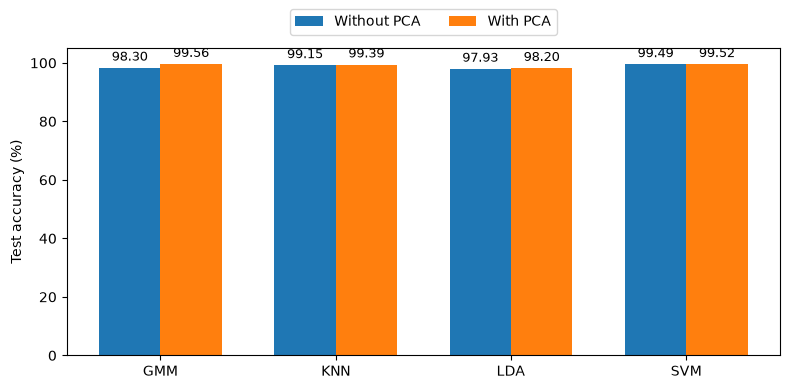

In [100]:
original_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                     [gmm_confusion, knn_confusion, lda_confusion, svm_confusion]]
pca_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                [gmm_pca_confusion, knn_pca_confusion, lda_pca_confusion, svm_pca_confusion]]
positions = np.arange(4)
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
original_bars = ax.bar(positions - width / 2, original_accuracy, width, label="Without PCA")
pca_bars = ax.bar(positions + width / 2, pca_accuracy, width, label="With PCA")
ax.bar_label(original_bars, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(pca_bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(positions, ["GMM", "KNN", "LDA", "SVM"])
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 105)
ax.set_yticks(np.arange(0, 101, 20))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=2)
plt.tight_layout()
plt.show()


## **TIDIGITS**

### **Load Data**

In [103]:
sequences = []
labels = []
for digit in [2,4,8]:
    with np.load(os.path.join(DATA_DIR, "tdigits", f"{digit}.npz")) as data:
        for key in data.files:
            sequences.append(data[key])
            labels.append(digit)

y = np.array(labels)

print("Recordings:", len(sequences))
print("Labels:", y.shape)


Recordings: 1350
Labels: (1350,)


### **Shuffle and Split**

In [104]:
indices = np.arange(len(y))
# Deterministic stratified split: within each class, every 5 consecutive
# samples go 3 -> train, 1 -> validation, 1 -> test (60/20/20).
slot = np.zeros(len(y), dtype=int)
for label in np.unique(y):
    members = indices[y == label]
    slot[members] = np.arange(len(members)) % 5

train_indices = indices[slot < 3]
val_indices = indices[slot == 3]
test_indices = indices[slot == 4]

y_train = y[train_indices]
y_val = y[val_indices]
y_test = y[test_indices]


### **Sequence Length Distribution**

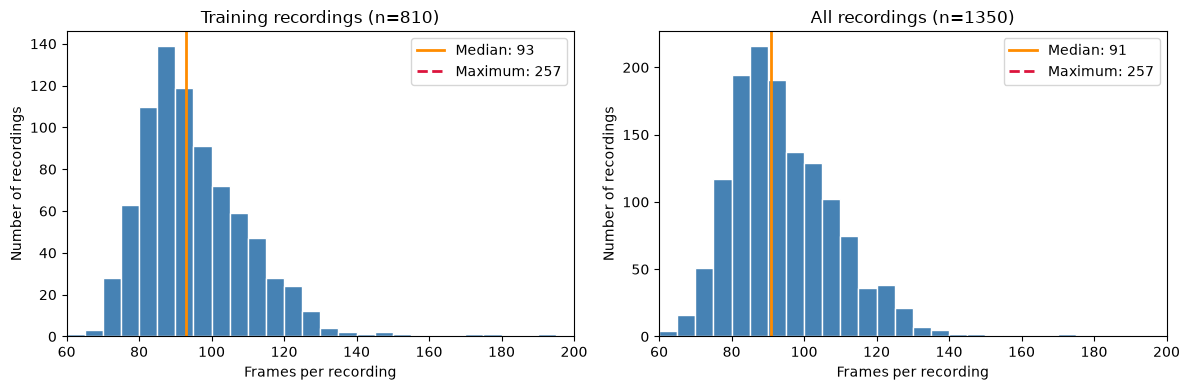

In [105]:
lengths = np.array([len(s) for s in sequences])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, values, title in zip(axes, [lengths[train_indices], lengths],
                            ["Training recordings", "All recordings"]):
    ax.hist(values, bins=np.arange(60, 201, 5), color="steelblue", edgecolor="white")
    ax.axvline(np.median(values), color="darkorange", linewidth=2,
               label=f"Median: {np.median(values):.0f}")
    ax.axvline(values.max(), color="crimson", linestyle="--", linewidth=2,
               label=f"Maximum: {values.max()}")
    ax.set_title(f"{title} (n={len(values)})")
    ax.set_xlabel("Frames per recording")
    ax.set_ylabel("Number of recordings")
    ax.set_xlim(60, 200)
    ax.legend()
plt.tight_layout()
plt.show()


In [106]:
# raw_train_sequences = [sequences[i] for i in train_indices]
# raw_val_sequences = [sequences[i] for i in val_indices]
# raw_test_sequences = [sequences[i] for i in test_indices]
# frame_length = int(np.quantile([len(s) for s in raw_train_sequences], q=0.95))
# print(frame_length)

### **Padding**

In [107]:
raw_train_sequences = [sequences[i] for i in train_indices]
raw_val_sequences = [sequences[i] for i in val_indices]
raw_test_sequences = [sequences[i] for i in test_indices]
frame_length = int(np.median([len(s) for s in raw_train_sequences]))
# frame_length = int(np.quantile([len(s) for s in raw_train_sequences], q=0.95))



def pad_sequences(recordings):
    padded = []
    for recording in recordings:
        values = np.zeros((frame_length, recording.shape[1]))
        count = min(len(recording), frame_length)
        values[:count] = recording[:count]
        padded.append(values)
    return padded


train_sequences = pad_sequences(raw_train_sequences)
val_sequences = pad_sequences(raw_val_sequences)
test_sequences = pad_sequences(raw_test_sequences)
X_train = np.array(train_sequences).reshape(len(train_sequences), -1)
X_val = np.array(val_sequences).reshape(len(val_sequences), -1)
X_test = np.array(test_sequences).reshape(len(test_sequences), -1)
print("Target frames:", frame_length)


Target frames: 93


In [108]:
X_train.shape

(810, 3627)

In [109]:
classes = np.unique(y_train)
print("Class order:", classes)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Class order: [2 4 8]
Train: (810, 3627)
Validation: (270, 3627)
Test: (270, 3627)


### **Training Coordinates for GMM and LDA**

In [110]:
feature_mean = X_train.mean(axis=0)
_, _, vectors = np.linalg.svd(X_train - feature_mean, full_matrices=False)
basis = vectors.T
X_train_gaussian = (X_train - feature_mean) @ basis
X_val_gaussian = (X_val - feature_mean) @ basis
X_test_gaussian = (X_test - feature_mean) @ basis
print("All training directions retained:", X_train_gaussian.shape)


All training directions retained: (810, 810)


### **2D PCA Visualization**

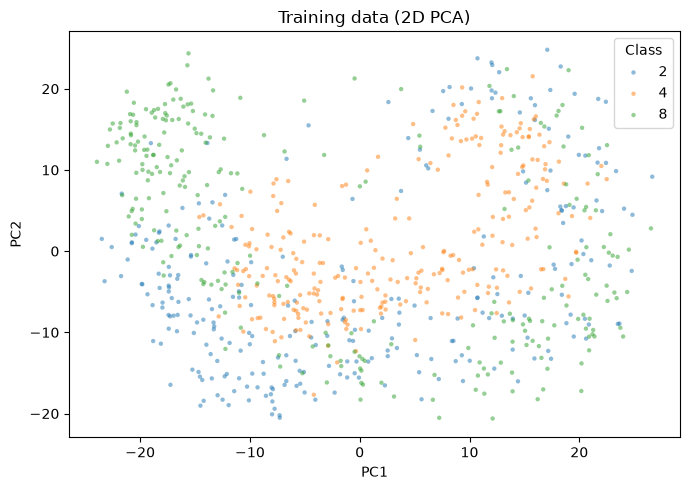

In [111]:
plot_pca_2d(X_train_gaussian, y_train)


### **GMM**

In [112]:
models = []
priors = []
for label in classes:
    samples = X_train_gaussian[y_train == label]
    model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    model.fit(samples)
    models.append(model)
    priors.append(len(samples) / len(X_train_gaussian))
    print("Class", label, "EM iterations:", len(model.log_likelihoods))
    if len(model.log_likelihoods) == model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 2 EM iterations: 2
Class 4 EM iterations: 2
Class 8 EM iterations: 2


In [113]:
val_scores = np.column_stack([model.score_samples(X_val_gaussian) for model in models])
gmm_val_predictions = classes[np.argmax(val_scores + np.log(priors), axis=1)]

test_scores = np.column_stack([model.score_samples(X_test_gaussian) for model in models])
gmm_test_predictions = classes[np.argmax(test_scores + np.log(priors), axis=1)]


In [114]:
# Confusion matrix
gmm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_confusion)


Validation accuracy: 0.937037037037037
Test accuracy: 0.9296296296296296
Test confusion matrix:
 [[88  1  1]
 [ 5 85  0]
 [10  2 78]]


### **KNN**

In [115]:
knn = KNN(k=5)
knn.fit(X_train, y_train)
knn_val_predictions = knn.predict(X_val)
knn_test_predictions = knn.predict(X_test)


In [116]:
# Confusion matrix
knn_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_test_predictions == y_test))
print("Test confusion matrix:\n", knn_confusion)


Validation accuracy: 0.9703703703703703
Test accuracy: 0.9555555555555556
Test confusion matrix:
 [[90  0  0]
 [ 5 85  0]
 [ 6  1 83]]


### **LDA**

In [117]:
lda = LDA()
lda.fit(X_train_gaussian, y_train)
lda_val_predictions = lda.predict(X_val_gaussian)
lda_test_predictions = lda.predict(X_test_gaussian)


In [118]:
# Confusion matrix
lda_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_test_predictions == y_test))
print("Test confusion matrix:\n", lda_confusion)


Validation accuracy: 0.8740740740740741
Test accuracy: 0.8518518518518519
Test confusion matrix:
 [[77  6  7]
 [ 6 79  5]
 [12  4 74]]


### **SVM**

In [119]:
svm = SVM()
svm.fit(X_train, y_train)
print("One-vs-rest classifiers:", len(svm.models))
print("Gaussian sigma:", svm.width)
print("Converged:", svm.converged)
print("Largest KKT gap:", max(svm.gaps))
if not svm.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_val_predictions = svm.predict(X_val)
svm_test_predictions = svm.predict(X_test)


One-vs-rest classifiers: 3
Gaussian sigma: 28.939738520160468
Converged: True
Largest KKT gap: 0.0009957942708715972


In [120]:
# Confusion matrix
svm_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_test_predictions == y_test))
print("Test confusion matrix:\n", svm_confusion)


Validation accuracy: 0.9407407407407408
Test accuracy: 0.9222222222222223
Test confusion matrix:
 [[80  6  4]
 [ 1 88  1]
 [ 5  4 81]]


### **PCA**

In [121]:
K = 39
pca = PCA(k=K)
pca.fit(X_train_gaussian)
X_train_pca = pca.transform(X_train_gaussian)
X_val_pca = pca.transform(X_val_gaussian)
X_test_pca = pca.transform(X_test_gaussian)

print("Train:", X_train_pca.shape)
print("Validation:", X_val_pca.shape)
print("Test:", X_test_pca.shape)


Train: (810, 39)
Validation: (270, 39)
Test: (270, 39)


### **GMM with PCA**

In [122]:
pca_models = []
pca_priors = []
for label in classes:
    pca_samples = X_train_pca[y_train == label]
    pca_model = GMM(K=3, reg=1e-3, max_iter=100, tol=1e-4)
    pca_model.fit(pca_samples)
    pca_models.append(pca_model)
    pca_priors.append(len(pca_samples) / len(X_train_pca))
    print("Class", label, "EM iterations:", len(pca_model.log_likelihoods))
    if len(pca_model.log_likelihoods) == pca_model.max_iter:
        print("Iteration limit reached; convergence is not guaranteed.")


Class 2 EM iterations: 4
Class 4 EM iterations: 2
Class 8 EM iterations: 2


In [123]:
pca_val_scores = np.column_stack([pca_model.score_samples(X_val_pca) for pca_model in pca_models])
gmm_pca_val_predictions = classes[np.argmax(pca_val_scores + np.log(pca_priors), axis=1)]

pca_test_scores = np.column_stack([pca_model.score_samples(X_test_pca) for pca_model in pca_models])
gmm_pca_test_predictions = classes[np.argmax(pca_test_scores + np.log(pca_priors), axis=1)]


In [124]:
# Confusion matrix
gmm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        gmm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (gmm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(gmm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(gmm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", gmm_pca_confusion)


Validation accuracy: 0.9703703703703703
Test accuracy: 0.9444444444444444
Test confusion matrix:
 [[84  1  5]
 [ 3 86  1]
 [ 5  0 85]]


### **KNN with PCA**

In [125]:
knn_pca = KNN(k=5)
knn_pca.fit(X_train_pca, y_train)
knn_pca_val_predictions = knn_pca.predict(X_val_pca)
knn_pca_test_predictions = knn_pca.predict(X_test_pca)


In [126]:
# Confusion matrix
knn_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        knn_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (knn_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(knn_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(knn_pca_test_predictions == y_test))
print("Test confusion matrix:\n", knn_pca_confusion)


Validation accuracy: 0.9629629629629629
Test accuracy: 0.9518518518518518
Test confusion matrix:
 [[83  2  5]
 [ 1 88  1]
 [ 3  1 86]]


### **LDA with PCA**

In [127]:
lda_pca = LDA()
lda_pca.fit(X_train_pca, y_train)
lda_pca_val_predictions = lda_pca.predict(X_val_pca)
lda_pca_test_predictions = lda_pca.predict(X_test_pca)


In [128]:
# Confusion matrix
lda_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        lda_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (lda_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(lda_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(lda_pca_test_predictions == y_test))
print("Test confusion matrix:\n", lda_pca_confusion)


Validation accuracy: 0.837037037037037
Test accuracy: 0.8333333333333334
Test confusion matrix:
 [[74  7  9]
 [ 5 78  7]
 [11  6 73]]


### **SVM with PCA**

In [129]:
svm_pca = SVM()
svm_pca.fit(X_train_pca, y_train)
print("One-vs-rest classifiers:", len(svm_pca.models))
print("Gaussian sigma:", svm_pca.width)
print("Converged:", svm_pca.converged)
print("Largest KKT gap:", max(svm_pca.gaps))
if not svm_pca.converged:
    print("Iteration limit reached; not a converged hard-margin solution.")
svm_pca_val_predictions = svm_pca.predict(X_val_pca)
svm_pca_test_predictions = svm_pca.predict(X_test_pca)


One-vs-rest classifiers: 3
Gaussian sigma: 19.187343040423762
Converged: True
Largest KKT gap: 0.0009952211373417397


In [130]:
# Confusion matrix
svm_pca_confusion = np.zeros((len(classes), len(classes)), dtype=int)
for i, actual in enumerate(classes):
    for j, predicted in enumerate(classes):
        svm_pca_confusion[i, j] = np.sum(
            (y_test == actual) & (svm_pca_test_predictions == predicted))

print("Validation accuracy:", np.mean(svm_pca_val_predictions == y_val))
print("Test accuracy:", np.mean(svm_pca_test_predictions == y_test))
print("Test confusion matrix:\n", svm_pca_confusion)


Validation accuracy: 0.9777777777777777
Test accuracy: 0.9407407407407408
Test confusion matrix:
 [[84  3  3]
 [ 1 88  1]
 [ 6  2 82]]


### **Accuracy Comparison**

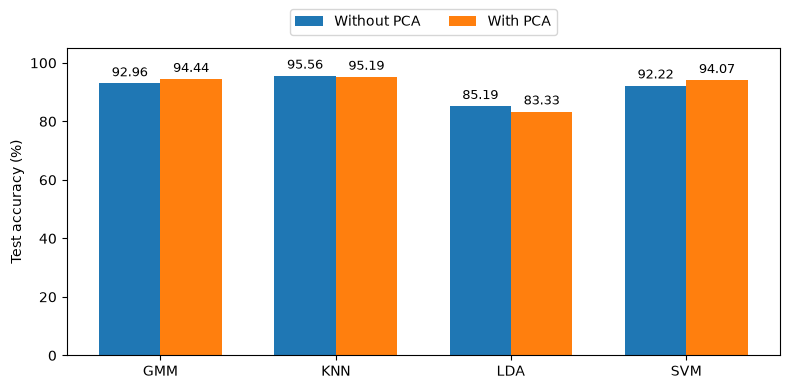

In [131]:
original_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                     [gmm_confusion, knn_confusion, lda_confusion, svm_confusion]]
pca_accuracy = [100 * np.trace(cm) / cm.sum() for cm in
                [gmm_pca_confusion, knn_pca_confusion, lda_pca_confusion, svm_pca_confusion]]
positions = np.arange(4)
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))
original_bars = ax.bar(positions - width / 2, original_accuracy, width, label="Without PCA")
pca_bars = ax.bar(positions + width / 2, pca_accuracy, width, label="With PCA")
ax.bar_label(original_bars, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(pca_bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(positions, ["GMM", "KNN", "LDA", "SVM"])
ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 105)
ax.set_yticks(np.arange(0, 101, 20))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=2)
plt.tight_layout()
plt.show()
